# Skill 5 – Case Study 2: Customer Churn Prediction

**Objective:** Identify customers at elevated risk of leaving so a retention team can prioritize outreach.

This notebook uses a reproducible **synthetic dataset of 6,000 customers** because no real customer dataset was supplied. The patterns are simulated for learning and are not evidence about a real company.

**Target:** `churned_within_30d` (1 = customer churns within 30 days after the decision snapshot; 0 = customer does not churn in that window).

## tl;dr

In this simulation, the 30-day churn rate is **13.15%**. Month-to-month customers have the highest contract-group churn (**19.92%**), while Electronic check customers have the highest payment-group churn (**17.19%**). The 7+ support-contact group has a **51.85%** churn rate.

Using the illustrative retention economics (₹50 outreach cost, ₹1,200 retained-customer value, and 25% save rate), the validation period selects a probability threshold of **0.53**. On the later test period, this threshold gives **65.3% recall**, **25.1% precision**, **0.298 PR-AUC**, and an estimated net benefit of **₹7,950** under those assumptions.

All figures are calculated from synthetic data. The estimated financial benefit is not a forecast; it depends directly on the assumed intervention cost, save rate and customer value.


## Context & Methods

### Business question
Which customers are at elevated risk of churning in the next 30 days, and how should a retention team prioritize limited outreach capacity?

### Decision point and grain
Each row represents one customer at a defined monthly decision snapshot. Predictors describe information available on that snapshot date. The target records whether the customer churns during the following 30 days.

### Key assumptions
- The dataset is synthetic and generated with a fixed random seed.
- Churn is a forward-looking 30-day outcome, not a status observed at the snapshot.
- Usage change compares the latest 30-day usage with the previous 30-day usage.
- A retention intervention costs **₹150** per contacted customer.
- A successfully retained customer is assigned an illustrative value of **₹1,200**.
- The intervention is assumed to successfully prevent churn for **25%** of customers who would otherwise churn and who receive outreach.
- These economic assumptions are illustrative and should be replaced with measured campaign costs, save rates and customer value before operational use.
- A chronological train/validation/test split is used. The validation period selects the outreach threshold; the later test period is held out for final evaluation.

## Data

### 1. Imports and reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
N_CUSTOMERS = 6000

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)

### 2. Generate a synthetic customer dataset

The customer snapshot contains contract, tenure, support, payment and usage information. The churn label and cancellation date occur after the snapshot. A post-churn status field is included only to demonstrate leakage; it must never be used as an earlier predictor.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

customer_id = np.arange(50001, 50001 + N_CUSTOMERS)

contract_type = rng.choice(
    ["Month-to-month", "One year", "Two year"],
    size=N_CUSTOMERS,
    p=[0.52, 0.28, 0.20]
)

payment_method = rng.choice(
    ["Electronic check", "Credit card", "Bank transfer", "Debit card"],
    size=N_CUSTOMERS,
    p=[0.32, 0.25, 0.25, 0.18]
)

tenure_months = rng.integers(1, 73, size=N_CUSTOMERS)

# Support contacts in the 90 days before the decision snapshot.
support_lambda = (
    0.7
    + 0.025 * (72 - tenure_months)
    + np.where(contract_type == "Month-to-month", 0.35, 0)
)
support_contacts_90d = rng.poisson(support_lambda)
support_contacts_90d = np.clip(support_contacts_90d, 0, 12)

# Monthly usage in arbitrary usage units. Compare two preceding 30-day periods.
previous_month_usage = rng.gamma(shape=4.0, scale=22.0, size=N_CUSTOMERS)
usage_change_signal = rng.normal(
    loc=-0.015, scale=0.18, size=N_CUSTOMERS
)
# More support contacts and shorter tenure are associated with greater usage decline.
usage_change_signal -= 0.012 * support_contacts_90d
usage_change_signal -= 0.0008 * (36 - tenure_months)
usage_change_signal = np.clip(usage_change_signal, -0.75, 0.75)

average_monthly_usage = np.maximum(
    1.0, previous_month_usage * (1 + usage_change_signal)
)
usage_change = (
    average_monthly_usage - previous_month_usage
) / previous_month_usage

# Simulated churn probability based on snapshot attributes.
contract_effect = pd.Series(contract_type).map({
    "Month-to-month": 0.95,
    "One year": -0.35,
    "Two year": -0.85
}).to_numpy()

payment_effect = pd.Series(payment_method).map({
    "Electronic check": 0.40,
    "Credit card": -0.10,
    "Bank transfer": -0.20,
    "Debit card": 0.05
}).to_numpy()

logit = (
    -2.15
    + contract_effect
    - 0.025 * tenure_months
    + 0.22 * support_contacts_90d
    - 1.8 * usage_change
    + payment_effect
)

churn_probability = 1 / (1 + np.exp(-logit))
churned_within_30d = rng.binomial(1, churn_probability)

# Monthly decision snapshots over one year.
snapshot_offsets = rng.integers(0, 365, size=N_CUSTOMERS)
snapshot_date = pd.Timestamp("2025-01-01") + pd.to_timedelta(snapshot_offsets, unit="D")

# Cancellation occurs after the snapshot only for customers who churn in the window.
days_to_cancel = rng.integers(1, 31, size=N_CUSTOMERS)
cancellation_date = pd.Series(
    pd.NaT, index=np.arange(N_CUSTOMERS), dtype="datetime64[ns]"
)
churn_indices = np.where(churned_within_30d == 1)[0]
cancellation_date.iloc[churn_indices] = (
    snapshot_date[churn_indices]
    + pd.to_timedelta(days_to_cancel[churn_indices], unit="D")
).to_numpy()

# This field reflects the outcome after the prediction window and is deliberately forbidden.
post_churn_status = np.where(churned_within_30d == 1, "Cancelled", "Active")

df = pd.DataFrame({
    "customer_id": customer_id,
    "snapshot_date": snapshot_date,
    "contract_type": contract_type,
    "tenure_months": tenure_months,
    "support_contacts_90d": support_contacts_90d,
    "payment_method": payment_method,
    "previous_month_usage": np.round(previous_month_usage, 2),
    "average_monthly_usage": np.round(average_monthly_usage, 2),
    "usage_change": np.round(usage_change, 4),
    "churned_within_30d": churned_within_30d.astype(int),
    "cancellation_date": cancellation_date,
    "post_churn_status": post_churn_status
})

# Add a small amount of missingness to snapshot predictors.
missing_usage_idx = rng.choice(df.index, size=60, replace=False)
missing_support_idx = rng.choice(df.index, size=45, replace=False)
df.loc[missing_usage_idx, "average_monthly_usage"] = np.nan
df.loc[missing_support_idx, "support_contacts_90d"] = np.nan

df.to_csv("customer_churn_synthetic.csv", index=False)

print("Synthetic customer dataset created.")
print("Shape:", df.shape)
display(df.head())

Synthetic customer dataset created.
Shape: (6000, 12)


,customer_id,snapshot_date,contract_type,tenure_months,support_contacts_90d,payment_method,previous_month_usage,average_monthly_usage,usage_change,churned_within_30d,cancellation_date,post_churn_status
0,50001,2025-03-09,One year,67,0.0,Credit card,160.06,105.21,-0.3427,0,NaT,Active
1,50002,2025-08-04,Month-to-month,38,0.0,Electronic check,144.63,84.33,-0.4169,0,NaT,Active
2,50003,2025-11-25,Two year,45,1.0,Credit card,141.88,133.06,-0.0622,0,NaT,Active
3,50004,2025-07-08,One year,26,1.0,Electronic check,106.36,110.73,0.0411,0,NaT,Active
4,50005,2025-08-30,Month-to-month,65,2.0,Electronic check,30.64,35.40,0.1552,0,NaT,Active


### 3. Validate the data

Check row grain, duplicate customers, data types, missingness, label values and basic numeric ranges.

In [3]:
print("Dataset shape (rows, columns):", df.shape)
print("\nData types and non-null counts:")
df.info()

print("\nDuplicate customer IDs:", df["customer_id"].duplicated().sum())
print("Duplicate full rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df["churned_within_30d"].value_counts().rename(index={0: "No churn", 1: "Churn"}).to_frame("customers"))

assert df["customer_id"].is_unique
assert set(df["churned_within_30d"].dropna().unique()).issubset({0, 1})
assert (df["tenure_months"] >= 1).all()
assert (df["support_contacts_90d"].dropna() >= 0).all()
assert (df["average_monthly_usage"].dropna() >= 0).all()

Dataset shape (rows, columns): (6000, 12)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
Index: 6000 entries, 0 to 5999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   customer_id            6000 non-null   int64         
 1   snapshot_date          6000 non-null   datetime64[ns]
 2   contract_type          6000 non-null   object        
 3   tenure_months          6000 non-null   int64         
 4   support_contacts_90d   5955 non-null   float64       
 5   payment_method         6000 non-null   object        
 6   previous_month_usage   6000 non-null   float64       
 7   average_monthly_usage  5940 non-null   float64       
 8   usage_change           6000 non-null   float64       
 9   churned_within_30d     6000 non-null   int64         
 10  cancellation_date      789 non-null    datetime64[ns]
 11  post_churn_status      6000 non-null   object      

,customers
churned_within_30d,
No churn,5211
Churn,789


## Results

## Task A – Exploratory Data Analysis

### 4. Overall churn rate and missing values

Overall 30-day churn rate: 13.15%


,missing_count,missing_percent
cancellation_date,5211,86.85
average_monthly_usage,60,1.00
support_contacts_90d,45,0.75
customer_id,0,0.00
tenure_months,0,0.00
contract_type,0,0.00
snapshot_date,0,0.00
payment_method,0,0.00
previous_month_usage,0,0.00
usage_change,0,0.00


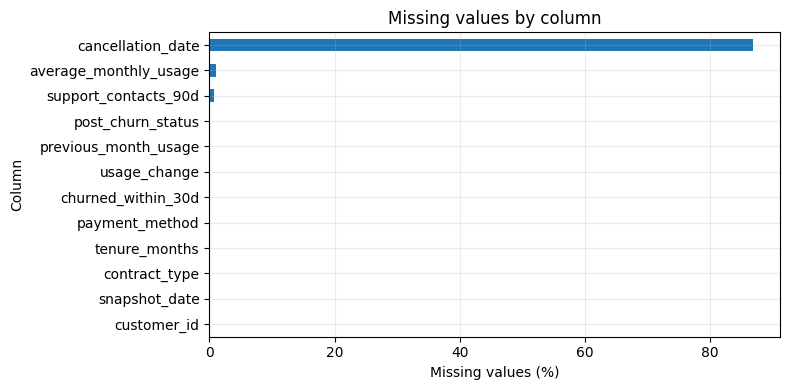

In [4]:
overall_churn_rate = df["churned_within_30d"].mean() * 100
print(f"Overall 30-day churn rate: {overall_churn_rate:.2f}%")

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

fig, ax = plt.subplots(figsize=(8, 4))
missing_summary["missing_percent"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Missing values by column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Column")
plt.tight_layout()
plt.show()

### 5. Churn rate by contract type

Contract type is a key segmentation variable. Compare churn rates alongside customer counts so that small groups are not over-interpreted.

,customers,churned,churn_rate_pct
contract_type,,,
Month-to-month,3177,633,19.92
One year,1650,107,6.48
Two year,1173,49,4.18


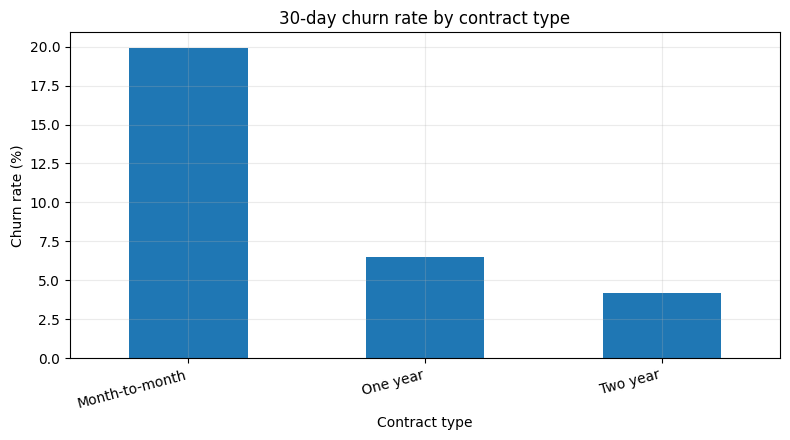

In [5]:
contract_summary = (
    df.groupby("contract_type", observed=True)
      .agg(customers=("customer_id", "count"),
           churned=("churned_within_30d", "sum"),
           churn_rate=("churned_within_30d", "mean"))
)
contract_summary["churn_rate_pct"] = contract_summary["churn_rate"] * 100
contract_summary = contract_summary.sort_values("churn_rate", ascending=False)

display(contract_summary[["customers", "churned", "churn_rate_pct"]].round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
contract_summary["churn_rate_pct"].plot(kind="bar", ax=ax)
ax.set_title("30-day churn rate by contract type")
ax.set_xlabel("Contract type")
ax.set_ylabel("Churn rate (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### 6. Churn rate by tenure

Tenure is grouped into interpretable ranges. The grouping is for EDA only; the model retains numeric `tenure_months`.

,customers,churned,churn_rate,churn_rate_pct
tenure_group,,,,
0–6 months,459,110,0.24,23.97
7–12 months,523,117,0.22,22.37
13–24 months,1013,176,0.17,17.37
25–48 months,2020,246,0.12,12.18
49–72 months,1985,140,0.07,7.05


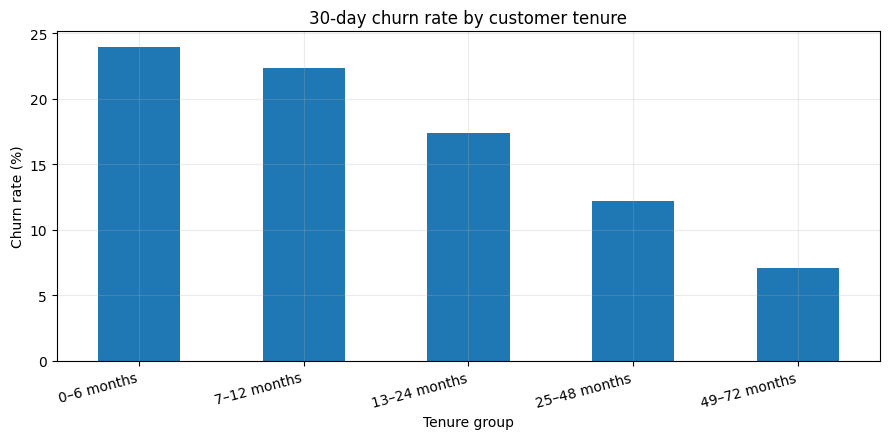

In [6]:
df["tenure_group"] = pd.cut(
    df["tenure_months"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=["0–6 months", "7–12 months", "13–24 months", "25–48 months", "49–72 months"]
)

tenure_summary = (
    df.groupby("tenure_group", observed=True)
      .agg(customers=("customer_id", "count"),
           churned=("churned_within_30d", "sum"),
           churn_rate=("churned_within_30d", "mean"))
)
tenure_summary["churn_rate_pct"] = tenure_summary["churn_rate"] * 100

display(tenure_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
tenure_summary["churn_rate_pct"].plot(kind="bar", ax=ax)
ax.set_title("30-day churn rate by customer tenure")
ax.set_xlabel("Tenure group")
ax.set_ylabel("Churn rate (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### 7. Churn rate by support contacts in the previous 90 days

More support contacts may indicate friction or unresolved problems. This is an association to investigate, not proof that support contacts cause churn.

,customers,churned,churn_rate,churn_rate_pct
support_contact_group,,,,
0,1116,73,0.07,6.54
1,1736,143,0.08,8.24
2–3,2386,375,0.16,15.72
4–6,690,179,0.26,25.94
7+,27,14,0.52,51.85


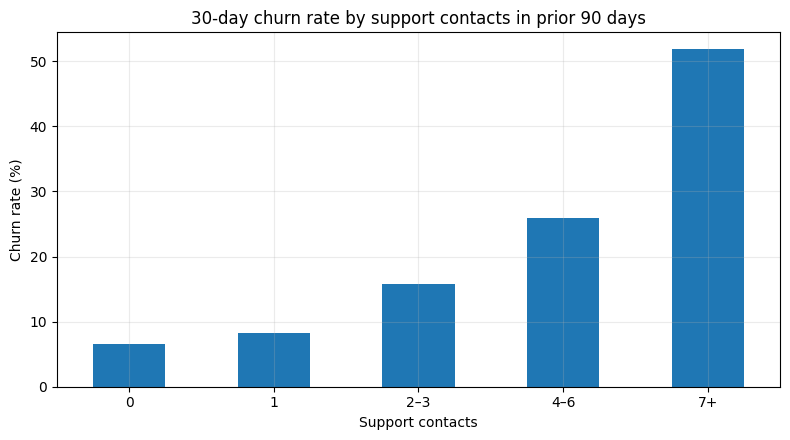

In [7]:
df["support_contact_group"] = pd.cut(
    df["support_contacts_90d"],
    bins=[-1, 0, 1, 3, 6, np.inf],
    labels=["0", "1", "2–3", "4–6", "7+"]
)

support_summary = (
    df.groupby("support_contact_group", observed=True)
      .agg(customers=("customer_id", "count"),
           churned=("churned_within_30d", "sum"),
           churn_rate=("churned_within_30d", "mean"))
)
support_summary["churn_rate_pct"] = support_summary["churn_rate"] * 100

display(support_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
support_summary["churn_rate_pct"].plot(kind="bar", ax=ax)
ax.set_title("30-day churn rate by support contacts in prior 90 days")
ax.set_xlabel("Support contacts")
ax.set_ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 8. Churn rate by payment method

,customers,churned,churn_rate_pct
payment_method,,,
Electronic check,1902,327,17.19
Debit card,1052,147,13.97
Credit card,1492,165,11.06
Bank transfer,1554,150,9.65


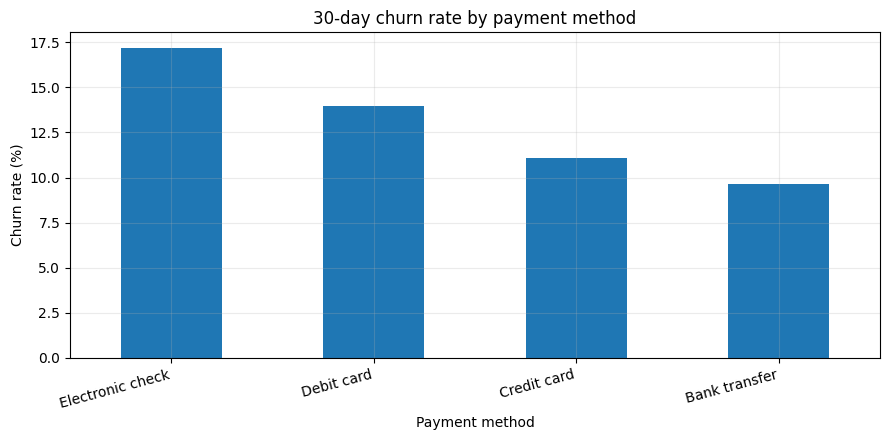

In [8]:
payment_summary = (
    df.groupby("payment_method", observed=True)
      .agg(customers=("customer_id", "count"),
           churned=("churned_within_30d", "sum"),
           churn_rate=("churned_within_30d", "mean"))
)
payment_summary["churn_rate_pct"] = payment_summary["churn_rate"] * 100
payment_summary = payment_summary.sort_values("churn_rate", ascending=False)

display(payment_summary[["customers", "churned", "churn_rate_pct"]].round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
payment_summary["churn_rate_pct"].plot(kind="bar", ax=ax)
ax.set_title("30-day churn rate by payment method")
ax.set_xlabel("Payment method")
ax.set_ylabel("Churn rate (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### 9. Usage patterns among churned and retained customers

Compare average monthly usage and usage change. `usage_change` is the relative change from the previous 30-day period to the latest 30-day period.

,customers,avg_monthly_usage,mean_usage_change,median_usage_change
churned_within_30d,,,,
No churn,5211,85.344,-0.030,-0.032
Churn,789,80.600,-0.098,-0.097


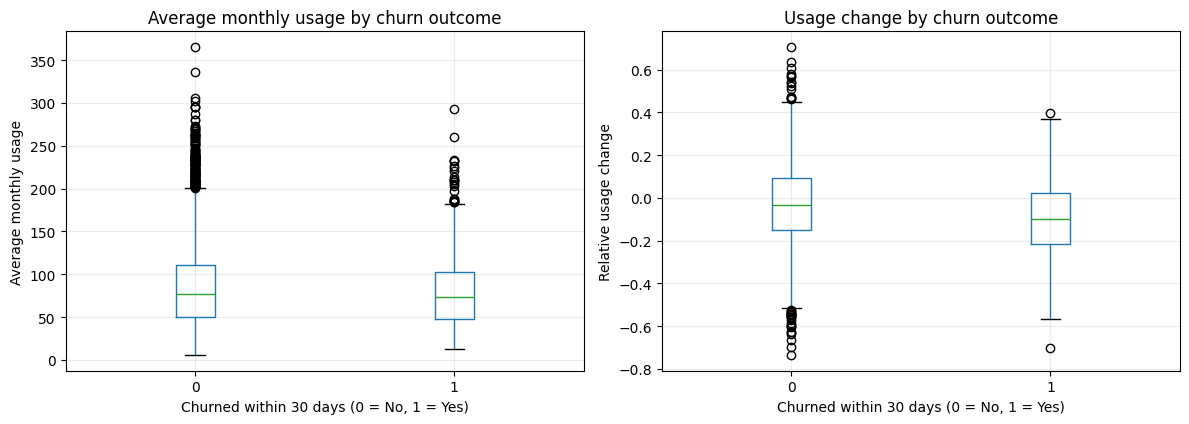

In [9]:
usage_summary = (
    df.groupby("churned_within_30d")
      .agg(customers=("customer_id", "count"),
           avg_monthly_usage=("average_monthly_usage", "mean"),
           mean_usage_change=("usage_change", "mean"),
           median_usage_change=("usage_change", "median"))
      .rename(index={0: "No churn", 1: "Churn"})
)
display(usage_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df.boxplot(column="average_monthly_usage", by="churned_within_30d", ax=axes[0])
axes[0].set_title("Average monthly usage by churn outcome")
axes[0].set_xlabel("Churned within 30 days (0 = No, 1 = Yes)")
axes[0].set_ylabel("Average monthly usage")
fig.suptitle("")

df.boxplot(column="usage_change", by="churned_within_30d", ax=axes[1])
axes[1].set_title("Usage change by churn outcome")
axes[1].set_xlabel("Churned within 30 days (0 = No, 1 = Yes)")
axes[1].set_ylabel("Relative usage change")
fig.suptitle("")
plt.tight_layout()
plt.show()

## Task B – Feature Engineering

### 10. Create the four requested predictors

The model features are:
- `tenure_months`
- `support_contacts_90d`
- `average_monthly_usage`
- `usage_change`

The last two are snapshot usage measures. `usage_change` compares the latest 30-day usage with the previous 30-day usage.

In [10]:
feature_columns = [
    "tenure_months",
    "support_contacts_90d",
    "average_monthly_usage",
    "usage_change"
]

display(df[["customer_id"] + feature_columns].head(10))
print("\nFeature missingness:")
display(df[feature_columns].isna().sum().to_frame("missing_count"))

,customer_id,tenure_months,support_contacts_90d,average_monthly_usage,usage_change
0,50001,67,0.0,105.21,-0.3427
1,50002,38,0.0,84.33,-0.4169
2,50003,45,1.0,133.06,-0.0622
3,50004,26,1.0,110.73,0.0411
4,50005,65,2.0,35.40,0.1552
5,50006,6,1.0,122.83,-0.0829
6,50007,20,3.0,32.23,-0.0194
7,50008,72,1.0,51.18,0.1433
8,50009,35,1.0,58.19,-0.0508
9,50010,13,6.0,55.82,0.0003



Feature missingness:


,missing_count
tenure_months,0
support_contacts_90d,45
average_monthly_usage,60
usage_change,0


### 11. Leakage check

A cancellation date and a post-churn account status are known only after the customer has churned. They cannot be used to predict churn at an earlier decision point.

The target label is also excluded from predictors. The model uses only the four snapshot features requested in the case study.

In [11]:
forbidden_predictors = [
    "cancellation_date",
    "post_churn_status",
    "churned_within_30d"
]

leakage_audit = pd.DataFrame({
    "field": forbidden_predictors,
    "why_excluded": [
        "Occurs after the prediction snapshot; directly reveals churn timing",
        "Reflects the account state after the outcome window",
        "This is the target label, not a predictor"
    ],
    "included_in_model": [False, False, False]
})
display(leakage_audit)

assert not any(col in feature_columns for col in forbidden_predictors)

,field,why_excluded,included_in_model
0,cancellation_date,Occurs after the prediction snapshot; directly...,False
1,post_churn_status,Reflects the account state after the outcome w...,False
2,churned_within_30d,"This is the target label, not a predictor",False


## Task C – Offline Evaluation Plan

### 12. Create chronological train, validation and test sets

- **Train (70%)**: fit preprocessing and the model.
- **Validation (15%)**: choose the outreach threshold based on the intervention economics.
- **Test (15%)**: final evaluation after the threshold has been selected.

This avoids selecting a threshold on the same observations used for the final test result.

In [12]:
model_df = df.sort_values("snapshot_date").reset_index(drop=True)

n = len(model_df)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
validation_df = model_df.iloc[train_end:validation_end].copy()
test_df = model_df.iloc[validation_end:].copy()

target_column = "churned_within_30d"

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_validation = validation_df[feature_columns]
y_validation = validation_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "rows": [len(train_df), len(validation_df), len(test_df)],
    "start_date": [
        train_df["snapshot_date"].min(),
        validation_df["snapshot_date"].min(),
        test_df["snapshot_date"].min()
    ],
    "end_date": [
        train_df["snapshot_date"].max(),
        validation_df["snapshot_date"].max(),
        test_df["snapshot_date"].max()
    ],
    "churn_rate_pct": [
        y_train.mean() * 100,
        y_validation.mean() * 100,
        y_test.mean() * 100
    ]
})
display(split_summary.round(2))

,split,rows,start_date,end_date,churn_rate_pct
0,Train,4200,2025-01-01,2025-09-16,13.17
1,Validation,900,2025-09-16,2025-11-07,12.78
2,Test,900,2025-11-07,2025-12-31,13.44


### 13. Build preprocessing and train a baseline plus Logistic Regression

Numeric missing values are imputed with the training median and standardized. The preprocessing pipeline is fitted only on the training data.

In [13]:
numeric_features = feature_columns

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features)
])

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

logistic_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

validation_probability = logistic_model.predict_proba(X_validation)[:, 1]
test_probability = logistic_model.predict_proba(X_test)[:, 1]

baseline_test_prediction = baseline.predict(X_test)

### 14. Compare classification metrics on the untouched test set

PR-AUC (average precision) is useful for imbalanced churn outcomes because it summarizes the precision-recall curve. Accuracy alone can hide poor identification of churners.

In [14]:
def classification_metrics(y_true, y_pred, y_score=None):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }
    metrics["pr_auc"] = (
        average_precision_score(y_true, y_score)
        if y_score is not None else np.nan
    )
    return metrics

test_prediction_05 = (test_probability >= 0.50).astype(int)

model_comparison = pd.DataFrame([
    {
        "model": "Majority-class baseline",
        **classification_metrics(y_test, baseline_test_prediction)
    },
    {
        "model": "Logistic Regression (threshold 0.50)",
        **classification_metrics(y_test, test_prediction_05, test_probability)
    }
]).set_index("model")

display((model_comparison * 100).round(2))

,accuracy,balanced_accuracy,precision,recall,f1,pr_auc
model,,,,,,
Majority-class baseline,86.56,50.00,0.00,0.00,0.00,NaN
Logistic Regression (threshold 0.50),64.67,67.02,23.16,70.25,34.84,29.78


### 15. Precision-recall curve

The curve shows the trade-off between identifying more churners (recall) and keeping outreach focused on customers who are more likely to churn (precision).

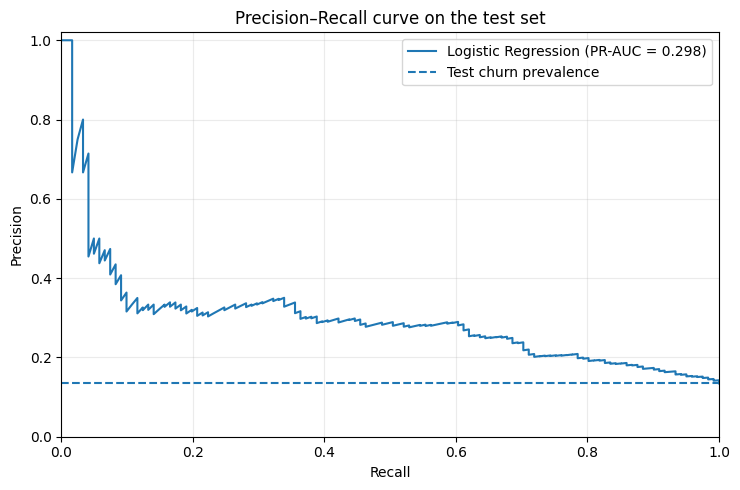

In [15]:
precision_values, recall_values, thresholds = precision_recall_curve(
    y_test, test_probability
)
test_pr_auc = average_precision_score(y_test, test_probability)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(recall_values, precision_values, label=f"Logistic Regression (PR-AUC = {test_pr_auc:.3f})")
ax.axhline(y_test.mean(), linestyle="--", label="Test churn prevalence")
ax.set_title("Precision–Recall curve on the test set")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend()
plt.tight_layout()
plt.show()

### 16. Select an outreach threshold using intervention cost/benefit

A threshold of 0.50 is not automatically the best operational choice. Here we select a threshold on the validation set using the stated assumptions:

- Low-cost intervention per contacted customer = ₹50.
- Value of a successfully retained customer = ₹1,200.
- Assumed intervention save rate among true at-risk customers = 25%.
- Expected value per correctly targeted churner = 25% × ₹1,200 = ₹300.
- Every contacted customer incurs the ₹150 intervention cost.

For each threshold:

**Expected net benefit = true positives × ₹300 − all contacted customers × ₹150**

This is a simplified expected-value model. It assumes a constant customer value and save rate and excludes longer-term effects.

In [16]:
INTERVENTION_COST = 50
RETAINED_CUSTOMER_VALUE = 1200
SAVE_RATE = 0.25

EXPECTED_VALUE_PER_TRUE_POSITIVE = SAVE_RATE * RETAINED_CUSTOMER_VALUE

threshold_grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
validation_threshold_rows = []

for threshold in threshold_grid:
    predicted_churn = (validation_probability >= threshold).astype(int)
    true_positive = int(((predicted_churn == 1) & (y_validation.to_numpy() == 1)).sum())
    contacted = int(predicted_churn.sum())
    false_positive = int(((predicted_churn == 1) & (y_validation.to_numpy() == 0)).sum())
    precision = precision_score(y_validation, predicted_churn, zero_division=0)
    recall = recall_score(y_validation, predicted_churn, zero_division=0)
    net_benefit = (
        true_positive * EXPECTED_VALUE_PER_TRUE_POSITIVE
        - contacted * INTERVENTION_COST
    )

    validation_threshold_rows.append({
        "threshold": threshold,
        "contacted": contacted,
        "true_positives": true_positive,
        "false_positives": false_positive,
        "precision": precision,
        "recall": recall,
        "expected_net_benefit_INR": net_benefit
    })

validation_threshold_results = pd.DataFrame(validation_threshold_rows)
best_row = validation_threshold_results.loc[
    validation_threshold_results["expected_net_benefit_INR"].idxmax()
]
selected_threshold = float(best_row["threshold"])

print(f"Selected validation threshold: {selected_threshold:.2f}")
print(f"Validation expected net benefit: ₹{best_row['expected_net_benefit_INR']:,.0f}")
display(best_row.to_frame("selected_threshold_result"))

Selected validation threshold: 0.53
Validation expected net benefit: ₹7,050


,selected_threshold_result
threshold,0.530000
contacted,309.000000
true_positives,75.000000
false_positives,234.000000
precision,0.242718
recall,0.652174
expected_net_benefit_INR,7050.000000


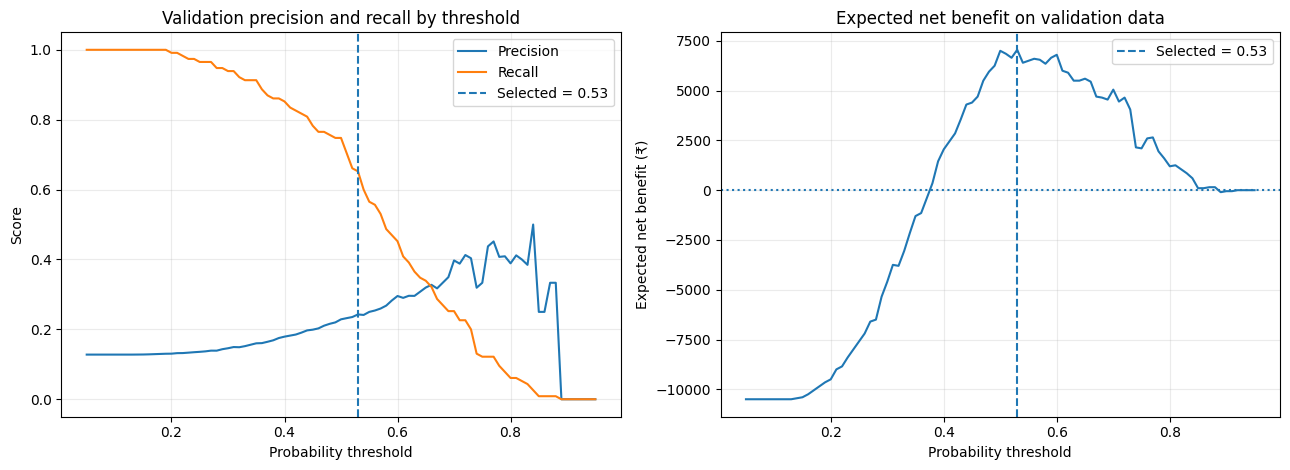

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(
    validation_threshold_results["threshold"],
    validation_threshold_results["precision"],
    label="Precision"
)
axes[0].plot(
    validation_threshold_results["threshold"],
    validation_threshold_results["recall"],
    label="Recall"
)
axes[0].axvline(selected_threshold, linestyle="--", label=f"Selected = {selected_threshold:.2f}")
axes[0].set_title("Validation precision and recall by threshold")
axes[0].set_xlabel("Probability threshold")
axes[0].set_ylabel("Score")
axes[0].legend()

axes[1].plot(
    validation_threshold_results["threshold"],
    validation_threshold_results["expected_net_benefit_INR"]
)
axes[1].axvline(selected_threshold, linestyle="--", label=f"Selected = {selected_threshold:.2f}")
axes[1].axhline(0, linestyle=":")
axes[1].set_title("Expected net benefit on validation data")
axes[1].set_xlabel("Probability threshold")
axes[1].set_ylabel("Expected net benefit (₹)")
axes[1].legend()

plt.tight_layout()
plt.show()

### 17. Evaluate the selected threshold on the untouched test set

The threshold is fixed from validation. It is now applied once to the test set to estimate how the policy may perform on later customers.

In [18]:
test_prediction_selected = (test_probability >= selected_threshold).astype(int)

selected_threshold_metrics = classification_metrics(
    y_test, test_prediction_selected, test_probability
)

test_tp = int(((test_prediction_selected == 1) & (y_test.to_numpy() == 1)).sum())
test_contacted = int(test_prediction_selected.sum())
test_fp = int(((test_prediction_selected == 1) & (y_test.to_numpy() == 0)).sum())
test_fn = int(((test_prediction_selected == 0) & (y_test.to_numpy() == 1)).sum())

test_expected_net_benefit = (
    test_tp * EXPECTED_VALUE_PER_TRUE_POSITIVE
    - test_contacted * INTERVENTION_COST
)

selected_test_summary = pd.DataFrame([{
    "selected_threshold": selected_threshold,
    "customers_tested": len(y_test),
    "customers_contacted": test_contacted,
    "true_positives": test_tp,
    "false_positives": test_fp,
    "missed_churners": test_fn,
    "precision": selected_threshold_metrics["precision"],
    "recall": selected_threshold_metrics["recall"],
    "f1": selected_threshold_metrics["f1"],
    "pr_auc": selected_threshold_metrics["pr_auc"],
    "expected_net_benefit_INR": test_expected_net_benefit
}])

display(selected_test_summary.round(3))
print(f"Expected net benefit on the test period: ₹{test_expected_net_benefit:,.0f}")

,selected_threshold,customers_tested,customers_contacted,true_positives,false_positives,missed_churners,precision,recall,f1,pr_auc,expected_net_benefit_INR
0,0.53,900,315,79,236,42,0.251,0.653,0.362,0.298,7950.0


Expected net benefit on the test period: ₹7,950


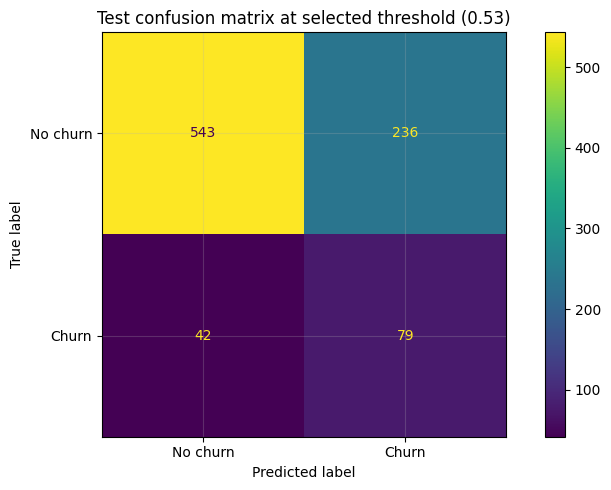

              precision    recall  f1-score   support

    No churn       0.93      0.70      0.80       779
       Churn       0.25      0.65      0.36       121

    accuracy                           0.69       900
   macro avg       0.59      0.67      0.58       900
weighted avg       0.84      0.69      0.74       900



In [19]:
cm = confusion_matrix(y_test, test_prediction_selected, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No churn", "Churn"]
)
disp.plot(values_format="d")
plt.title(f"Test confusion matrix at selected threshold ({selected_threshold:.2f})")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    test_prediction_selected,
    target_names=["No churn", "Churn"],
    zero_division=0
))

### 18. Compare the selected outreach policy with contacting nobody

A positive expected net benefit is not guaranteed. This comparison uses the same assumptions and the same test population. It does not account for capacity constraints or variation in customer lifetime value.

,policy,contacted_customers,expected_net_benefit_INR
0,No outreach,0,0.0
1,Model-prioritized outreach,315,7950.0


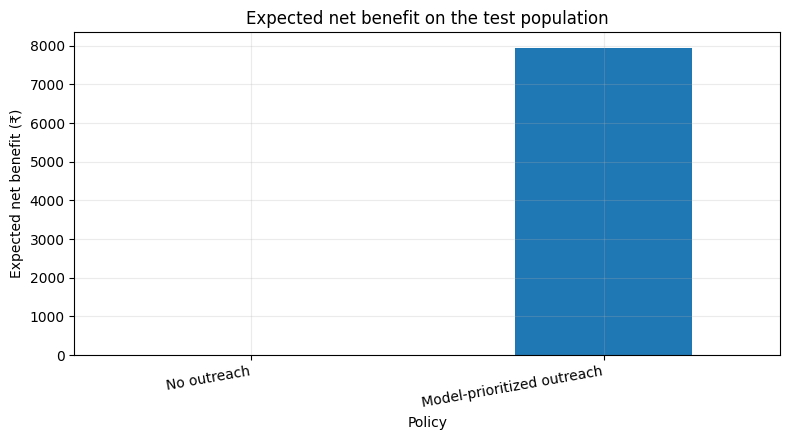

In [20]:
policy_comparison = pd.DataFrame({
    "policy": ["No outreach", "Model-prioritized outreach"],
    "contacted_customers": [0, test_contacted],
    "expected_net_benefit_INR": [0, test_expected_net_benefit]
})

display(policy_comparison)

fig, ax = plt.subplots(figsize=(8, 4.5))
policy_comparison.set_index("policy")["expected_net_benefit_INR"].plot(kind="bar", ax=ax)
ax.set_title("Expected net benefit on the test population")
ax.set_xlabel("Policy")
ax.set_ylabel("Expected net benefit (₹)")
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()

### 19. Inspect model coefficients

Logistic Regression coefficients show the direction of association after scaling. Positive coefficients increase predicted churn odds; negative coefficients decrease them. These are model associations, not causal effects.

,feature,coefficient
1,num__support_contacts_90d,0.369
3,num__usage_change,-0.328
0,num__tenure_months,-0.326
2,num__average_monthly_usage,0.051


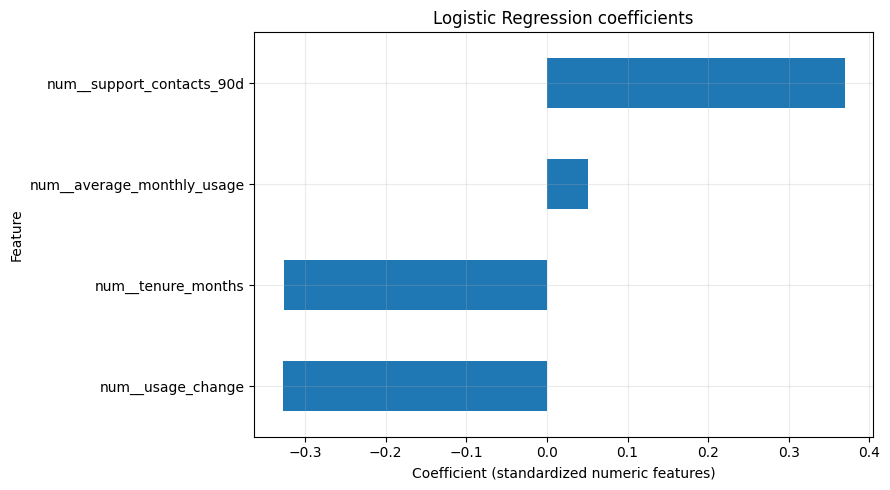

In [21]:
fitted_preprocessor = logistic_model.named_steps["preprocessing"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = logistic_model.named_steps["classifier"].coef_[0]

coefficient_table = (
    pd.DataFrame({
        "feature": feature_names,
        "coefficient": coefficients
    })
    .assign(abs_coefficient=lambda x: x["coefficient"].abs())
    .sort_values("abs_coefficient", ascending=False)
)

display(coefficient_table.drop(columns="abs_coefficient").round(3))

fig, ax = plt.subplots(figsize=(9, 5))
coefficient_table.sort_values("coefficient").plot(
    kind="barh", x="feature", y="coefficient", legend=False, ax=ax
)
ax.set_title("Logistic Regression coefficients")
ax.set_xlabel("Coefficient (standardized numeric features)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

## Takeaways

### 20. Evidence-backed findings

The following cell summarizes the executed synthetic data. The results describe this simulation only.

In [22]:
highest_contract = contract_summary["churn_rate_pct"].idxmax()
highest_contract_rate = contract_summary.loc[highest_contract, "churn_rate_pct"]

highest_payment = payment_summary["churn_rate_pct"].idxmax()
highest_payment_rate = payment_summary.loc[highest_payment, "churn_rate_pct"]

highest_support = support_summary["churn_rate_pct"].idxmax()
highest_support_rate = support_summary.loc[highest_support, "churn_rate_pct"]

print("SYNTHETIC DATA FINDINGS")
print(f"1. Overall 30-day churn rate: {overall_churn_rate:.2f}%.")
print(f"2. Highest churn contract group: {highest_contract} ({highest_contract_rate:.2f}%).")
print(f"3. Highest churn payment group: {highest_payment} ({highest_payment_rate:.2f}%).")
print(f"4. Highest churn support-contact group: {highest_support} ({highest_support_rate:.2f}%).")
print(f"5. Validation-selected outreach threshold: {selected_threshold:.2f}.")
print(f"6. Test PR-AUC: {selected_threshold_metrics['pr_auc']:.3f}.")
print(f"7. Test recall at selected threshold: {selected_threshold_metrics['recall']:.3f}.")
print(f"8. Test precision at selected threshold: {selected_threshold_metrics['precision']:.3f}.")
print(f"9. Test expected net benefit under assumptions: ₹{test_expected_net_benefit:,.0f}.")

SYNTHETIC DATA FINDINGS
1. Overall 30-day churn rate: 13.15%.
2. Highest churn contract group: Month-to-month (19.92%).
3. Highest churn payment group: Electronic check (17.19%).
4. Highest churn support-contact group: 7+ (51.85%).
5. Validation-selected outreach threshold: 0.53.
6. Test PR-AUC: 0.298.
7. Test recall at selected threshold: 0.653.
8. Test precision at selected threshold: 0.251.
9. Test expected net benefit under assumptions: ₹7,950.


### 21. Recommendations

Use the computed findings to guide investigation. The following are hypotheses to validate with real customer and campaign data:

- Review month-to-month contract customers for pricing, value perception and renewal friction.
- Investigate repeated support contacts to identify unresolved issues and service recovery opportunities.
- Examine usage declines as a possible early warning signal, while checking whether the pattern differs by product or customer segment.
- Review payment-method differences for payment failures, friction or customer mix before changing payment experiences.
- Prioritize outreach using a threshold that reflects the real cost of contacting customers and the value of retaining them.
- Test retention offers with a randomized holdout group to measure incremental saves rather than assuming every contacted at-risk customer can be retained.

### 22. Limitations

1. **Synthetic data:** The observed rates and model metrics are illustrative only.
2. **Simplified churn definition:** Churn is defined as cancellation within 30 days after the snapshot.
3. **Customer value is constant:** Real customer lifetime value varies by segment and should be modeled or estimated.
4. **Intervention effectiveness is assumed:** A 25% save rate is not measured from a randomized campaign.
5. **No capacity constraint:** The model does not impose a maximum number of customers the retention team can contact.
6. **Temporal validation:** One chronological split is a first check. Production evaluation should use rolling time windows.
7. **Model calibration:** Predicted probabilities should be calibrated and checked before being interpreted as actual churn probabilities.
8. **Causality:** Segment and coefficient differences are associations, not proof of causal churn drivers.
9. **Fairness and customer experience:** Outreach policies should be reviewed for disparate impact, customer fatigue and inappropriate targeting.

### 23. Proposed offline and business evaluation plan

1. Define a consistent decision snapshot (for example, the first day of each month).
2. Create features only from data available on or before that snapshot.
3. Label churn as cancellation during the following 30 days.
4. Exclude customers whose 30-day outcome window is incomplete.
5. Use rolling chronological train, validation and test windows.
6. Compare a simple baseline with Logistic Regression and a tree-based model.
7. Report precision, recall, F1, PR-AUC, calibration and the number of customers contacted.
8. Choose the threshold using measured intervention costs, incremental save rates and customer value.
9. Evaluate the campaign with a randomized holdout to measure incremental retention and net value.
10. Monitor model drift, feature freshness, threshold performance and customer-contact fatigue.

### 24. Final conclusion

This case study demonstrates how customer churn can be explored through contract, tenure, support contacts and payment method; how snapshot usage features can be engineered; and how an imbalanced classification model can support retention prioritization. Precision and recall should be considered together, while PR-AUC measures ranking performance across thresholds. The outreach threshold should reflect intervention economics and be selected on validation data before final testing. All numerical results in this notebook are synthetic and must be replaced with real, time-aligned customer data before business use.